In [97]:


# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Model
from sklearn.linear_model import LogisticRegression


# Train-Test Split
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.preprocessing import StandardScaler

# Evaluation Metrics
from sklearn.metrics import classification_report, confusion_matrix,roc_curve,roc_auc_score


In [124]:
df = pd.read_csv('Cardiovascular_Disease.csv')
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1


# Data Cleaning

In [99]:
# Convert age from dyas to years
df['age'] = df['age']/365

In [100]:
# Removing Outliers
#sns.boxplot(df['height']) # 150 - 185
#sns.bosplot(df['weight'])# 45 - 120
# sns.boxplot(df['ap_hi'])# 90-190
# sns.boxplot(df['ap_lo'])# 50 - 90
df = df[
 (df['height'].between(150, 185)) &
(df['weight'].between(45, 120))&
    (df['ap_hi'].between(90, 190))&
    (df['ap_lo'].between(50,90))


    
]

In [101]:
df

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50.391781,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55.419178,1,156,85.0,140,90,3,1,0,0,1,1
2,2,51.663014,1,165,64.0,130,70,3,1,0,0,0,1
4,4,47.873973,1,156,56.0,100,60,1,1,0,0,0,0
5,8,60.038356,1,151,67.0,120,80,2,2,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69994,99992,57.736986,1,165,80.0,150,80,1,1,0,0,1,1
69995,99993,52.712329,2,168,76.0,120,80,1,1,1,0,1,0
69997,99996,52.235616,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,61.454795,1,163,72.0,135,80,1,2,0,0,0,1


# Feauture and Target


In [102]:
features = ['age', 'gender', 'weight', 'ap_hi', 'ap_lo',
            'cholesterol', 'gluc', 'smoke', 'alco', 'active']

target = 'cardio'

X = df[features]
Y = df[target]

In [103]:
print(X.head())
print(Y.head())

         age  gender  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  alco  \
0  50.391781       2    62.0    110     80            1     1      0     0   
1  55.419178       1    85.0    140     90            3     1      0     0   
2  51.663014       1    64.0    130     70            3     1      0     0   
4  47.873973       1    56.0    100     60            1     1      0     0   
5  60.038356       1    67.0    120     80            2     2      0     0   

   active  
0       1  
1       1  
2       0  
4       0  
5       0  
0    0
1    1
2    1
4    0
5    0
Name: cardio, dtype: int64


In [104]:
print(X.shape)
print(Y.shape)

(61311, 10)
(61311,)


# Train Test Split

In [105]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

# feature Scaling

In [106]:
scaler = StandardScaler()

X_train_scale = scaler.fit_transform(X_train)

X_test_scale = scaler.transform(X_test)

## Model Implementation

In [107]:
model = LogisticRegression(
    solver='lbfgs',
    class_weight='balanced',
    random_state=42
)

In [108]:
model.fit(X_train_scale, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


# prediction

In [109]:
Y_pred = model.predict(X_test_scale)
Y_pred

array([0, 1, 0, ..., 1, 1, 0], shape=(12263,))

In [110]:
print(classification_report(Y_test, Y_pred))

              precision    recall  f1-score   support

           0       0.72      0.76      0.74      6471
           1       0.72      0.67      0.69      5792

    accuracy                           0.72     12263
   macro avg       0.72      0.72      0.72     12263
weighted avg       0.72      0.72      0.72     12263



# Metrics

In [111]:
cr = classification_report(Y_test, Y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.72      0.76      0.74      6471
           1       0.72      0.67      0.69      5792

    accuracy                           0.72     12263
   macro avg       0.72      0.72      0.72     12263
weighted avg       0.72      0.72      0.72     12263



In [112]:
'''
-Macro Avg:(val1 + val2+....+val_n )/ num_of _classes
-weighted Avg : (val1 * support)+ (val2 * support)+....+(val_n * support)/ total_support
'''
# macro = (0.76 + 0.67)/2
# macro

# weight = ((0.76*6538)+(0.67*5725))/12263
# weight

'\n-Macro Avg:(val1 + val2+....+val_n )/ num_of _classes\n-weighted Avg : (val1 * support)+ (val2 * support)+....+(val_n * support)/ total_support\n'

In [113]:
cm = confusion_matrix(Y_test, Y_pred)

print(cm)

[[4934 1537]
 [1910 3882]]


In [114]:
tn, fp, fn,tp = cm.ravel()
print(f'True Negative:{tn}')
print(f'False Positive:{fp}')
print(f'False Negative:{fn}')
print(f'True Positive:{tp}')

True Negative:4934
False Positive:1537
False Negative:1910
True Positive:3882


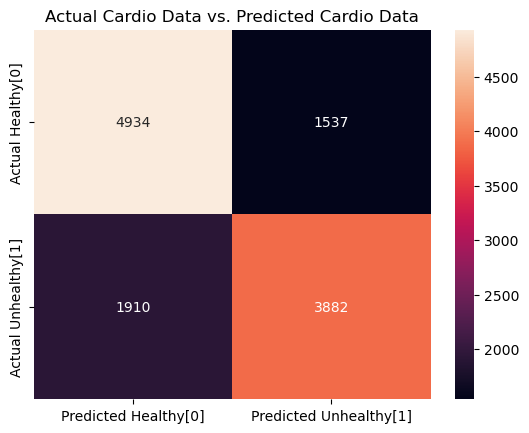

In [115]:
sns.heatmap(
    cm,
    annot=True,
    fmt="1.0f",
    xticklabels=["Predicted Healthy[0]", "Predicted Unhealthy[1]"],
    yticklabels=["Actual Healthy[0]", "Actual Unhealthy[1]"],
)
plt.title("Actual Cardio Data vs. Predicted Cardio Data")
plt.show()

## Clacuulation  for ROC - AUC curve

### Probalility Calculation`

In [116]:
Y_prob = model.predict_proba(X_test_scale)[:,1]
Y_prob

array([0.25767517, 0.52302167, 0.4681698 , ..., 0.57714913, 0.59429839,
       0.29487535], shape=(12263,))

# Roc ad Auc Values

In [117]:
fpr, tpr,threshold = roc_curve(Y_test,Y_prob)
auc_score = roc_auc_score(Y_test,Y_prob)

print(f'False Positive Rate:{fpr}')
print(f'True Positive Rate:{tpr}')
print(f'Threshold:{threshold}')

print(f'AUC Score:{auc_score}')

False Positive Rate:[0.0000000e+00 1.5453562e-04 1.5453562e-04 ... 9.9505486e-01 9.9505486e-01
 1.0000000e+00]
True Positive Rate:[0.         0.         0.00120856 ... 0.9996547  1.         1.        ]
Threshold:[       inf 0.99389501 0.98602304 ... 0.04591705 0.04487507 0.02763983]
AUC Score:0.7803842590102379


### Calculation of Actual Threshold Position

In [118]:
j_score = tpr - fpr
best_idx = np.argmax(j_score)

best_tpr = tpr[best_idx]
best_fpr = fpr[best_idx]
best_threshold = threshold[best_idx]

## ROC AUC Diagram

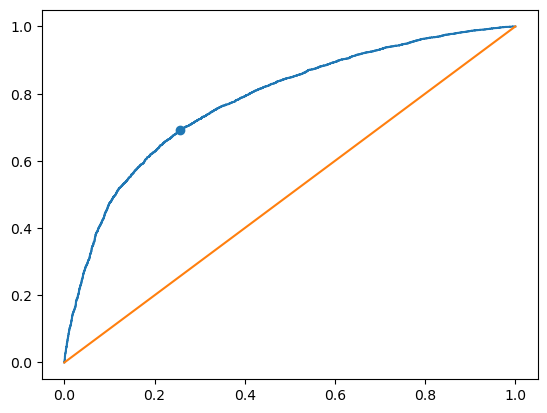

In [119]:
plt.plot(fpr,tpr)
plt.plot([0,1],[0,1])
plt.scatter(best_fpr,best_tpr)

### Setting New Calculated Threshold for prediction

In [120]:
Y_pred_prob =(Y_prob >= best_threshold).astype(int)
Y_pred_prob

array([0, 1, 0, ..., 1, 1, 0], shape=(12263,))

In [122]:
new_cr = classification_report(Y_test, Y_pred_prob)
new_cm = confusion_matrix(Y_test,Y_pred_prob)

print(new_cr)
print(new_cm)

              precision    recall  f1-score   support

           0       0.73      0.74      0.74      6471
           1       0.71      0.69      0.70      5792

    accuracy                           0.72     12263
   macro avg       0.72      0.72      0.72     12263
weighted avg       0.72      0.72      0.72     12263

[[4819 1652]
 [1791 4001]]
